<a href="https://colab.research.google.com/github/Divyajyothi-J/AI-mini-projects/blob/main/Divyajyothi_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Minor Project
Predictive Classification using Random Forest Ensembles

Import libraries

In [3]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

from google.colab import files

OUTPUT_DIR = "random_forest_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Load your uploaded Titanic dataset

In [4]:

# Load the uploaded Titanic dataset

CSV_PATH = "titanic-train.csv"

if not os.path.exists(CSV_PATH):
    uploaded = files.upload()

    csv_files = [
        name for name in uploaded.keys()
        if name.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError("Please upload your Titanic CSV file.")

    CSV_PATH = csv_files[0]

df = pd.read_csv(CSV_PATH)

# Remove accidental spaces in column names
df.columns = df.columns.str.strip()

if "Survived" not in df.columns:
    raise ValueError(
        "The dataset must contain the target column 'Survived'."
    )

print("Dataset loaded successfully!")
print("File:", CSV_PATH)
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: titanic-train.csv
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Inspect the dataset

In [5]:

# Dataset overview

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nSurvival counts:")
print(df["Survived"].value_counts())

print("\nSurvival proportions:")
print(df["Survived"].value_counts(normalize=True).round(3))

Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    i

,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0



Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival proportions:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


Exploratory Data Analysis: target distribution

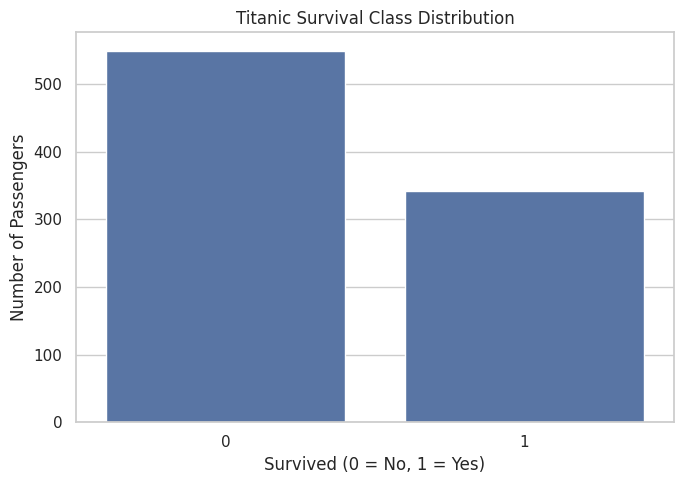

In [6]:

# Target class distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Survived")

plt.title("Titanic Survival Class Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "eda_target_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Correlation heatmap

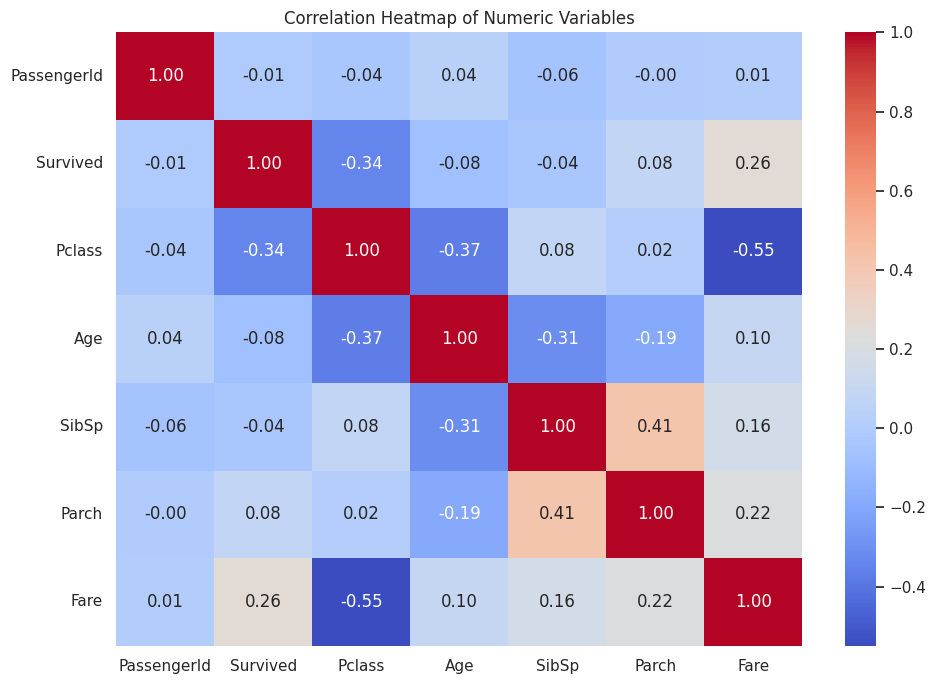

In [7]:

# Correlation heatmap

numeric_for_corr = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_for_corr.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "eda_correlation_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Feature distribution analysis

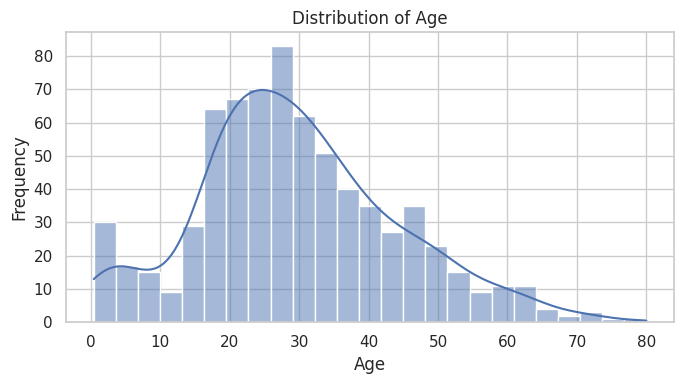

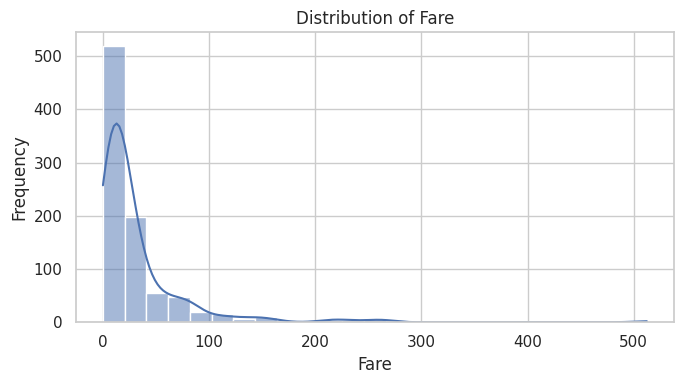

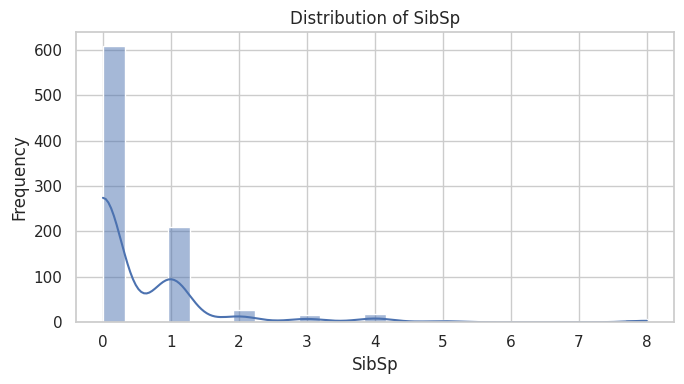

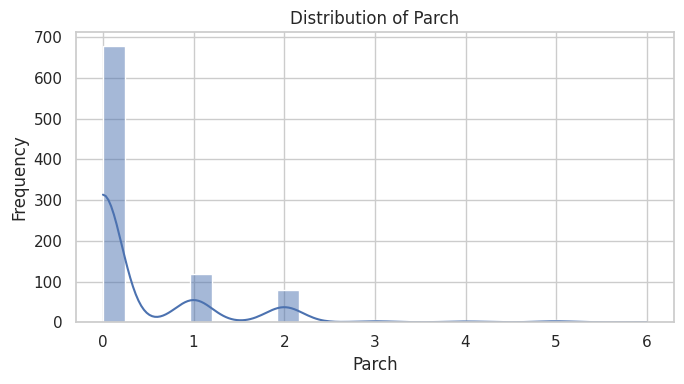

In [8]:

# Analyze numerical feature distributions

numeric_columns = [
    col for col in ["Age", "Fare", "SibSp", "Parch"]
    if col in df.columns
]

for col in numeric_columns:
    plt.figure(figsize=(7, 4))

    sns.histplot(df[col].dropna(), kde=True, bins=25)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, f"distribution_{col}.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Select features and target

In [9]:

# Feature selection

candidate_features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

missing_features = [
    col for col in candidate_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing expected columns: {missing_features}"
    )

# Remove rows with a missing target
df = df.dropna(subset=["Survived"]).copy()

# Ensure the target is binary
df["Survived"] = pd.to_numeric(
    df["Survived"], errors="raise"
).astype(int)

if not set(df["Survived"].unique()).issubset({0, 1}):
    raise ValueError("Survived must contain only 0 and 1.")

X = df[candidate_features].copy()
y = df["Survived"].copy()

print("Selected features:")
print(candidate_features)

print("\nFeature preview:")
display(X.head())

Selected features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Feature preview:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


Handle missing values and encode categorical features

The preprocessing pipeline fills missing numerical values with the median and categorical values with the most frequent value. One-Hot Encoding converts categories into numerical inputs.

In [10]:

# Identify numerical and categorical features

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline created successfully!")

Numerical features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Sex', 'Embarked']
Preprocessing pipeline created successfully!


Split the dataset into training and testing sets

We use the required 80:20 split, with stratification to preserve the survival-class proportions.

In [11]:

# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 712
Testing rows: 179

Training class proportions:
Survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Testing class proportions:
Survived
0    0.615
1    0.385
Name: proportion, dtype: float64


Random Forest model development

Hyperparameter justification for report:

n_estimators=300: builds 300 decision trees to create a more stable ensemble.

max_depth=None: allows each tree to grow until its stopping conditions are met. This can capture complex patterns but may increase overfitting risk.

class_weight="balanced": adjusts class weights according to their frequencies.

random_state=42: makes the experiment reproducible.

In [12]:

# Build the Random Forest pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Evaluation metrics

In [13]:

# Make predictions

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

# Display metrics
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

print("Random Forest Evaluation Results:")
display(metrics_df.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=[
        "Did not survive (0)",
        "Survived (1)"
    ],
    zero_division=0
))

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "evaluation_metrics.csv"),
    index=False
)

Random Forest Evaluation Results:


,Metric,Score
0,Accuracy,0.8268
1,Precision,0.8167
2,Recall,0.7101
3,F1-Score,0.7597
4,ROC-AUC,0.8328



Classification Report:
                     precision    recall  f1-score   support

Did not survive (0)       0.83      0.90      0.86       110
       Survived (1)       0.82      0.71      0.76        69

           accuracy                           0.83       179
          macro avg       0.82      0.81      0.81       179
       weighted avg       0.83      0.83      0.82       179



Confusion matrix heatmap

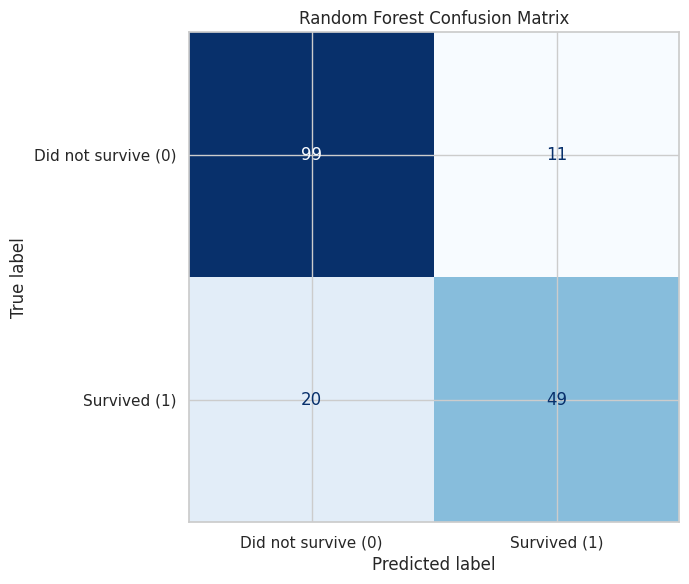

True Negatives (TN): 99
False Positives (FP): 11
False Negatives (FN): 20
True Positives (TP): 49


In [14]:

# Confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Did not survive (0)",
        "Survived (1)"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

ROC curve and AUC

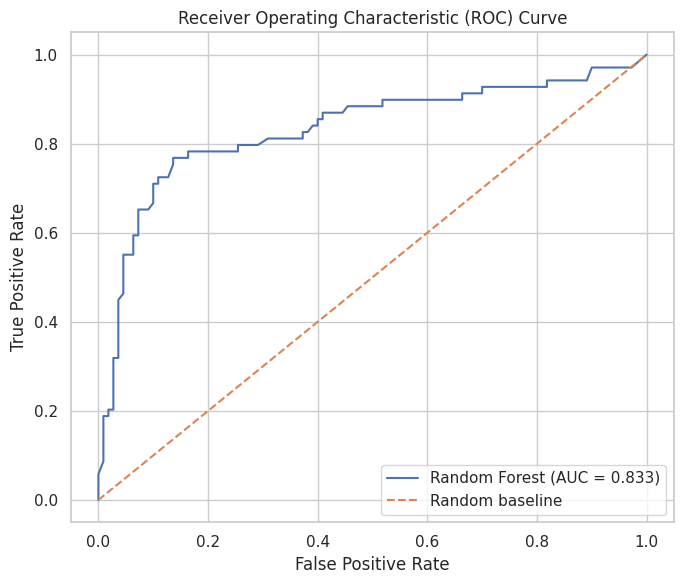

Final ROC-AUC Score: 0.8328


In [15]:

# ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Final ROC-AUC Score: {auc:.4f}")

Feature importance

Top 15 Feature Importances:


,Feature,Importance
4,num__Fare,0.2623
1,num__Age,0.2555
5,cat__Sex_female,0.1510
6,cat__Sex_male,0.1330
0,num__Pclass,0.0788
2,num__SibSp,0.0473
3,num__Parch,0.0359
9,cat__Embarked_S,0.0166
7,cat__Embarked_C,0.0124
8,cat__Embarked_Q,0.0070


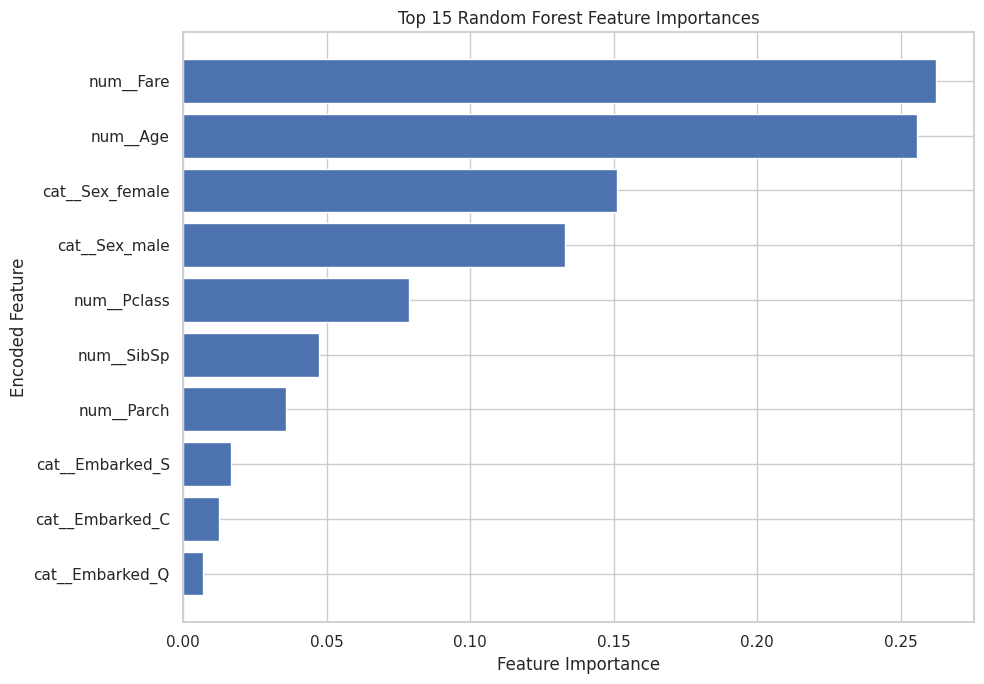

In [16]:

# Feature importance

fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

encoded_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

print("Top 15 Feature Importances:")
display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Encoded Feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "feature_importance.csv"),
    index=False
)

Save test predictions

In [17]:

# Save actual and predicted survival values

predictions_df = pd.DataFrame({
    "Actual_Survived": y_test.to_numpy(),
    "Predicted_Survived": y_pred,
    "Probability_Survived": y_prob
})

predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

display(predictions_df.head(10))

print("Predictions saved successfully!")

,Actual_Survived,Predicted_Survived,Probability_Survived
0,0,0,0.163333
1,0,0,0.111265
2,1,0,0.083333
3,0,0,0.043541
4,1,1,0.870000
5,1,0,0.283333
6,1,1,0.880000
7,0,1,0.850000
8,0,0,0.440000
9,0,0,0.297045


Predictions saved successfully!
